# 04 · Graph neural network experiment

A GNN treats drugs as nodes and known interactions as edges, so it can score
pairs it has never seen using each drug's neighbourhood. This notebook reviews
the committed results in `ml/artifacts/`; retraining needs the full interaction
graph (see `ml/training/train_gnn.py`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "ml").exists() else Path.cwd().parent
ARTIFACTS = ROOT / "ml" / "artifacts"

## Evaluation metrics

In [2]:
gnn = json.loads((ARTIFACTS / "gnn_eval_results.json").read_text())
pd.Series(gnn, name="GNN").to_frame()

,GNN
accuracy,0.999855
macro_f1,0.549964
interaction_f1,0.100000
auc,0.942726
ap,0.027335
severity_mae,0.414903


## Comparison with XGBoost

In [3]:
comparison = json.loads((ARTIFACTS / "eval" / "model_comparison.json").read_text())
table = pd.DataFrame({k: v for k, v in comparison.items() if isinstance(v, dict)}).T
table

,accuracy,macro_f1,macro_auc,auc,severity_mae
xgboost,0.998523,0.428325,0.991161,NaN,NaN
gnn,0.999855,0.549964,NaN,0.942726,0.414903


In [4]:
print(comparison["recommendation"])

XGBoost as primary (higher AUC, faster inference, SHAP explainability). GNN as secondary for novel/unseen drug pairs via graph neighbourhood.


## Training curve

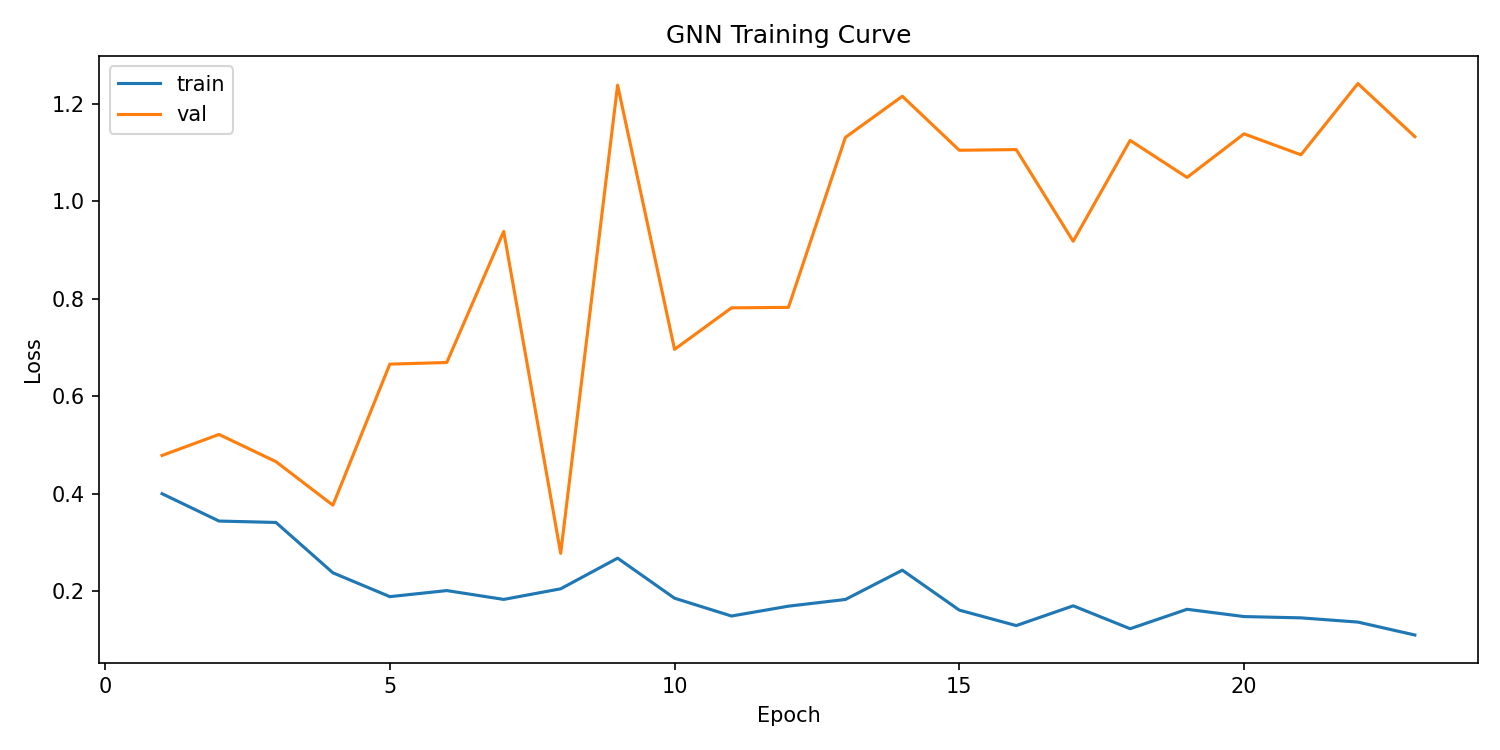

In [5]:
from IPython.display import Image
Image(filename=str(ARTIFACTS / "gnn_training_curve.png"), width=700)

## What the results say

- **Overfitting.** Training loss keeps falling while validation loss is lowest
  around epoch 8 and climbs after that. Early stopping (patience 15) halted
  training at epoch 23 and the epoch-8 checkpoint is the one saved, but the
  noisy, rising validation curve points to more regularisation (dropout,
  weight decay, edge dropout) and a smaller learning rate.
- **Interaction class is weak.** Interaction F1 is 0.10 and average precision is
  about 0.03. The near-perfect accuracy again reflects class imbalance: almost
  every candidate pair is a non-interaction.
- **Role in the system.** XGBoost stays the primary model (better macro AUC,
  SHAP explanations, fast inference). The GNN is kept as a secondary signal for
  drug pairs with no direct feature coverage.

## Next steps
1. Stronger regularisation and a lower starting learning rate.
2. Negative sampling at a realistic ratio and focal loss for the rare class.
3. Report precision@k on held-out interactions, which matches how alerts are used.